In [1]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
import sys
print(sys.version)
sys.path.append("../scripts")

3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]


In [9]:
# import necessary libraries
import cobra as cb
import numpy as np
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
import os
import textwrap
from scipy.sparse import issparse
from pathlib import Path



In [11]:
dir_path = Path().resolve().parent
dir_path

PosixPath('/home/sadegh/projects/Endometriosis-Classification-on-Transcriptomics-and-multimodal-data')

In [7]:
# import local functions from scFBApy for flux generation
from utils_scFBApy import scFBApy, repairNeg, popModel

In [12]:
# loading the flux model for flux generation
flux_model = cb.io.read_sbml_model(dir_path / "models/model.xml")
print("✅ FLux Model loaded with", len(flux_model.reactions), "reactions")

✅ FLux Model loaded with 449 reactions


# Import HECA dataset

In [13]:
adata = sc.read_h5ad(dir_path / "datasets/HECA-Subset.h5ad")
print("✅ HECA AnnData loaded with shape:", adata.shape)

✅ HECA AnnData loaded with shape: (90001, 17736)


In [14]:
adata

AnnData object with n_obs × n_vars = 90001 × 17736
    obs: 'n_genes', 'sample', 'percent_mito', 'n_counts', 'Endometriosis_stage', 'Endometriosis', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Age', 'lineage', 'celltype', 'label_long'
    var: 'gene_ids', 'feature_types'
    uns: 'Binary Stage_colors', 'Biopsy_type_colors', 'Endometrial_pathology_colors', 'Endometriosis_stage_colors', 'GarciaAlonso_celltype_colors', 'Group_colors', 'Hormonal treatment_colors', 'Library_genotype_colors', 'Mareckova_celltype_colors', 'Mareckova_epi_celltype_colors', 'Mareckova_lineage_colors', 'Processing_colors', 'Symbol_colors', 'Tan_cellsubtypes_colors', 'Tan_celltype_colors', 'Treatment_colors', 'celltype_colors', 'dataset_colors', 'genotype_colors', 'hvg', 'label_long_colors', 'leiden', 'leiden_R_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'phase_colors', 'umap'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'connectivities', 'distances'

In [15]:
# Unique cell types
cell_types = adata.obs['celltype'].unique()
print("🔢 Number of unique cell types:", len(cell_types))
print("\n📋 List of cell types:")
print(cell_types)

🔢 Number of unique cell types: 36

📋 List of cell types:
['Arterial', 'Ciliated', 'Cycling', 'Fibroblast_basalis', 'Glandular', ..., 'preGlandular', 'preLuminal', 'sHormones', 'uSMCs', 'dHormones']
Length: 36
Categories (36, object): ['SOX9_basalis', 'SOX9_functionalis_I', 'SOX9_functionalis_II', 'SOX9_luminal', ..., 'Immune_Myeloid', 'Venous', 'Arterial', 'Lymphatic']


In [16]:
# Count of cells per cell type
cell_type_counts = adata.obs['celltype'].value_counts()
print("\n📊 Cell counts per cell type:")
print(cell_type_counts)


📊 Cell counts per cell type:
celltype
eStromal                    15964
dStromal_mid                12571
Immune_Lymphoid              9891
dStromal_early               4824
Venous                       4447
eHormones                    4129
Glandular                    3746
SOX9_functionalis_II         3612
dStromal_late                3505
preGlandular                 3399
Immune_Myeloid               3232
Luminal                      2942
Glandular_secretory          2472
eStromal_cycling             2222
ePV_2                        2013
Ciliated                     1503
sHormones                    1186
Cycling                      1185
eStromal_MMPs                1146
ePV_1b                        790
preLuminal                    785
SOX9_luminal                  775
Arterial                      487
SOX9_functionalis_I           456
MUC5B                         399
uSMCs                         397
ePV_1a                        397
mPV                           389
HOXA13   

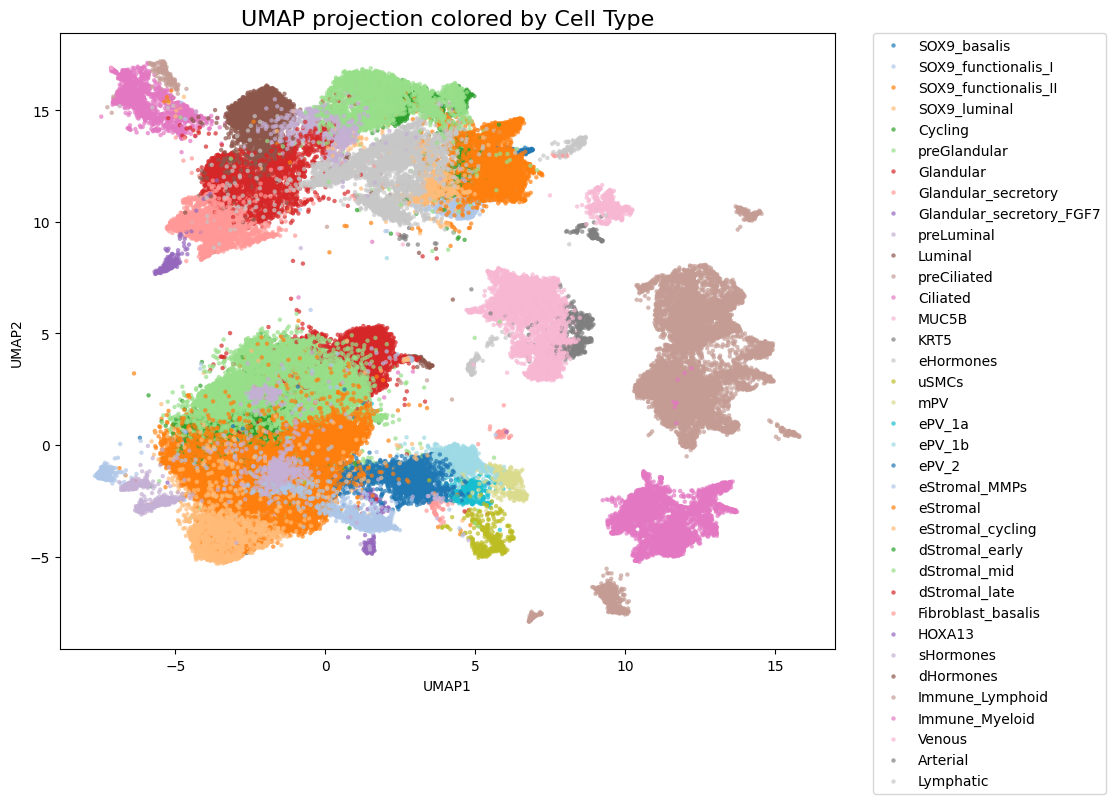

In [17]:
umap_df = pd.DataFrame(adata.obsm['X_umap'], columns=["UMAP1", "UMAP2"])
umap_df['celltype'] = adata.obs['celltype'].values

plt.figure(figsize=(10,8))
sns.scatterplot(
    data=umap_df, x="UMAP1", y="UMAP2",
    hue="celltype", palette="tab20", s=10, alpha=0.7, linewidth=0
)
plt.title("UMAP projection colored by Cell Type", fontsize=16)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()


# Working with three cell types

Endometriosis    Control  Endometriosis
celltype_simple                        
Glandular           4700           1749
Immune_Myeloid       915           2317
eStromal           10796           8536


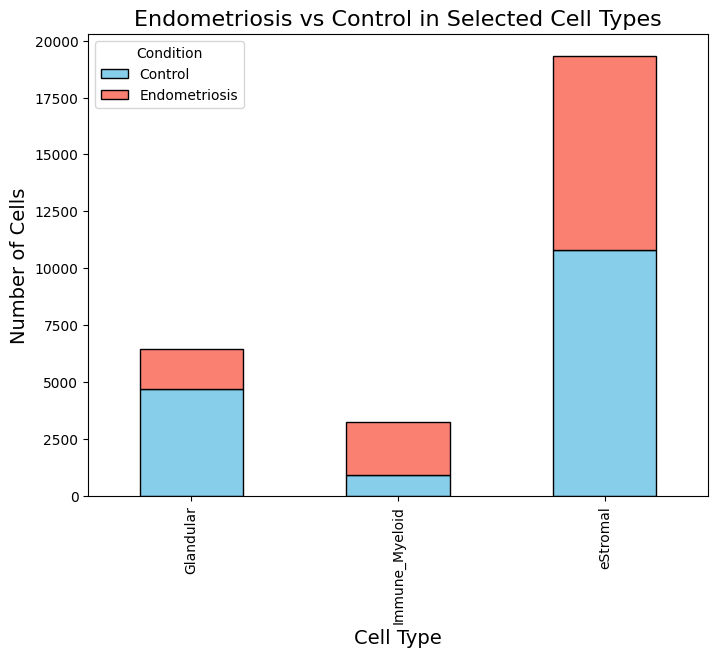

In [18]:
# Copy the obs dataframe
obs_df = adata.obs.copy()

# Collapse subtypes into main groups
def simplify_celltype(ct):
    if ct.startswith("eStromal"):
        return "eStromal"
    elif ct.startswith("Glandular"):
        return "Glandular"
    elif ct.startswith("Immune_Myeloid"):
        return "Immune_Myeloid"
    else:
        return None  

obs_df["celltype_simple"] = obs_df["celltype"].apply(simplify_celltype)

# Keep only selected groups
subset = obs_df[obs_df["celltype_simple"].notnull()]

# Count Endometriosis vs Control
cell_counts = subset.groupby(["celltype_simple", "Endometriosis"]).size().unstack(fill_value=0)

print(cell_counts)

# Plot
cell_counts.plot(kind="bar", stacked=True, figsize=(8,6), color=["skyblue", "salmon"], edgecolor="black")
plt.title("Endometriosis vs Control in Selected Cell Types", fontsize=16)
plt.ylabel("Number of Cells", fontsize=14)
plt.xlabel("Cell Type", fontsize=14)
plt.legend(title="Condition")
plt.show()


# Subset Creation

In [19]:
# Define the target cell types
target_cell_types = ["eStromal", "Glandular", "Immune_Myeloid"]

# Create a subset AnnData with only the selected cell types
subset_adata = adata[adata.obs["celltype"].isin(target_cell_types)].copy()

print("✅ Subset created!")
print("Shape:", subset_adata.shape)  # (n_obs, n_vars)
print("Cell type distribution:")
print(subset_adata.obs["celltype"].value_counts())

✅ Subset created!
Shape: (22942, 17736)
Cell type distribution:
celltype
eStromal          15964
Glandular          3746
Immune_Myeloid     3232
Name: count, dtype: int64


In [20]:
# Function to compute variance of each row (cell)
def compute_variance(row, label, endo_mean, control_mean):
    ref = endo_mean if label == "Endometriosis" else control_mean
    return np.mean((row - ref) ** 2)

selected_indices = []

for cell_type in target_cell_types:
    # Work with just this cell type
    ct_data = subset_adata[subset_adata.obs["celltype"] == cell_type]
    df_ct = pd.DataFrame(ct_data.X.toarray(), index=ct_data.obs_names, columns=ct_data.var_names)
    df_ct["Endometriosis"] = ct_data.obs["Endometriosis"].values

    # Compute group means
    endo_mean = df_ct[df_ct["Endometriosis"] == "Endometriosis"].drop("Endometriosis", axis=1).mean()
    control_mean = df_ct[df_ct["Endometriosis"] == "Control"].drop("Endometriosis", axis=1).mean()

    # Calculate variance for each cell
    df_ct["variance"] = df_ct.drop("Endometriosis", axis=1).apply(
        lambda row: compute_variance(row, df_ct.loc[row.name, "Endometriosis"], endo_mean, control_mean),
        axis=1
    )

    # For each class, select top 100 cells by variance
    for condition in ["Endometriosis", "Control"]:
        top_cells = (
            df_ct[df_ct["Endometriosis"] == condition]
            .sort_values("variance", ascending=False)
            .head(60)
            .index
        )
        selected_indices.extend(top_cells)

# Create new AnnData subset with 600 cells
final_subset_adata = subset_adata[selected_indices].copy()

print("✅ Final subset created by variance selection!")
print("Shape:", final_subset_adata.shape)  
print("\nCell distribution:\n")
print(final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size())

✅ Final subset created by variance selection!
Shape: (360, 17736)

Cell distribution:

celltype        Endometriosis
Glandular       Control          60
                Endometriosis    60
eStromal        Control          60
                Endometriosis    60
Immune_Myeloid  Control          60
                Endometriosis    60
dtype: int64



Cell distribution:

Endometriosis   Control  Endometriosis
celltype                              
Glandular            60             60
eStromal             60             60
Immune_Myeloid       60             60


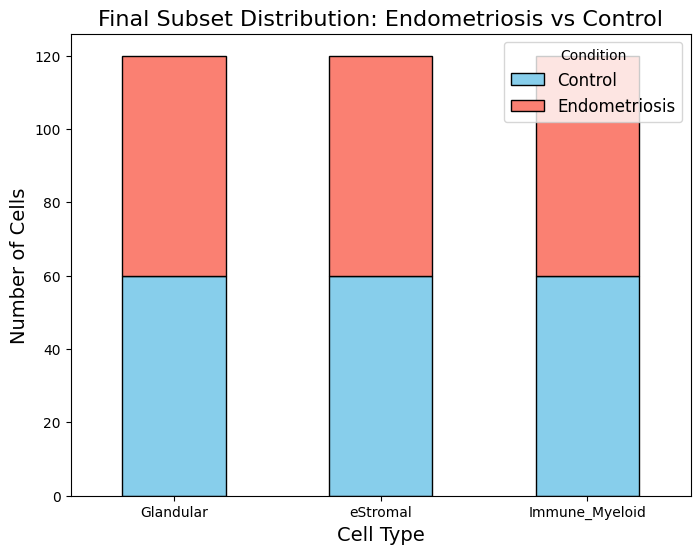

In [21]:
# Group by cell type and condition
cell_distribution = final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size().unstack(fill_value=0)

print("\nCell distribution:\n")
print(cell_distribution)

# Plot stacked bar chart
cell_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(8,6),
    color=["skyblue", "salmon"],
    edgecolor="black"
)

plt.title("Final Subset Distribution: Endometriosis vs Control", fontsize=16)
plt.ylabel("Number of Cells", fontsize=14)
plt.xlabel("Cell Type", fontsize=14)
plt.legend(title="Condition", fontsize=12)
plt.xticks(rotation=0)

# Save as PDF
plt.savefig("subset_distribution.pdf", format="pdf", bbox_inches="tight")

plt.show()


# Flux Generation

In [22]:
final_subset_adata

AnnData object with n_obs × n_vars = 360 × 17736
    obs: 'n_genes', 'sample', 'percent_mito', 'n_counts', 'Endometriosis_stage', 'Endometriosis', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Age', 'lineage', 'celltype', 'label_long'
    var: 'gene_ids', 'feature_types'
    uns: 'Binary Stage_colors', 'Biopsy_type_colors', 'Endometrial_pathology_colors', 'Endometriosis_stage_colors', 'GarciaAlonso_celltype_colors', 'Group_colors', 'Hormonal treatment_colors', 'Library_genotype_colors', 'Mareckova_celltype_colors', 'Mareckova_epi_celltype_colors', 'Mareckova_lineage_colors', 'Processing_colors', 'Symbol_colors', 'Tan_cellsubtypes_colors', 'Tan_celltype_colors', 'Treatment_colors', 'celltype_colors', 'dataset_colors', 'genotype_colors', 'hvg', 'label_long_colors', 'leiden', 'leiden_R_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'phase_colors', 'umap'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'connectivities', 'distances'

In [23]:
final_subset_adata.var_names = final_subset_adata.var["gene_ids"].astype(str)

In [ ]:
# Generate fluxes
adata_fluxes = scFBApy(
    model_orig=flux_model,
    adata=final_subset_adata,
    objective="Biomass",
    cooperation=True,
    eps=0.001,
    compute_fva=True,
    npop_fva=5,
    type_ras_normalization="max",
    and_expression=np.nanmin,
    or_expression=np.nansum,
    fraction_of_optimum=0,
    processes=1,
    round_c=10
)

print("✅ Flux analysis done")
print("📦 Mean biomass per cell:", adata_fluxes.to_df()["Biomass"].mean())

In [ ]:
# Extract flux results as a dataframe
flux_df = adata_fluxes.to_df()

# Save to CSV
flux_df.to_csv("top_60_flux_results.csv")

print("✅ Flux results saved as top_60_flux_results.csv")

In [25]:
flux_df = pd.read_csv(dir_path / 'preprocessed_data/top_60_flux_results.csv')

In [26]:
flux_df

,Unnamed: 0,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,...,PRAGSr,HMR_1504,EX_gthrd_e_#,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT
0,cell0,0.000151,0.001000,0.000000,-0.813034,0.000000,0.000143,0.0,0.001000,-0.000213,...,0.000151,0.000027,0.0,-0.019516,0.001000,0.000055,0.000000,0.000027,-0.000000,0.000055
1,cell1,0.000922,2.922510,0.000000,-0.813034,0.001000,-0.000000,0.0,0.001000,-0.001804,...,0.000922,0.000167,0.0,-4.284792,-0.001000,0.000333,0.001000,0.000167,-0.001000,0.000333
2,cell2,0.000922,0.013331,0.000000,-0.813034,0.000000,0.000107,0.0,0.001000,-0.001304,...,0.000922,0.000167,0.0,-0.000005,0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
3,cell3,0.000922,0.001000,0.000000,-0.813034,0.000000,0.000135,0.0,0.001000,-0.001304,...,0.000922,0.000167,0.0,0.001368,-0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
4,cell4,0.000083,0.000461,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000182,...,0.000083,0.000015,0.0,0.000849,-0.000877,0.000030,0.000000,0.000015,0.000466,0.000030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,cell355,0.000088,0.000957,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000124,...,0.000088,0.000016,0.0,0.001510,0.000321,0.000032,0.000039,0.000016,-0.001000,0.000032
356,cell356,0.000126,0.001000,0.000000,-0.813034,0.000000,-0.000055,0.0,0.001000,-0.000178,...,0.000126,0.000023,0.0,-0.014972,0.001000,0.000046,0.001000,0.000023,0.001000,0.000046
357,cell357,0.000098,0.000000,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001643,-0.000227,...,0.000098,0.000018,0.0,0.000293,0.000230,0.000035,0.000000,0.000018,-0.001000,0.000035
358,cell358,0.000107,0.000170,0.000000,-0.813034,0.000000,-0.000143,0.0,0.000000,-0.000253,...,0.000107,0.000019,0.0,-0.001114,0.001000,0.000039,0.000000,0.000019,0.000000,0.000039


# Classification on only transcriptomics data

In [27]:
train_cells = []
test_cells = []

# Loop through each cell type
for cell_type in ["eStromal", "Glandular", "Immune_Myeloid"]:
    subset = final_subset_adata[final_subset_adata.obs["celltype"] == cell_type]

    for cls in ["Endometriosis", "Control"]:
        cls_subset = subset[subset.obs["Endometriosis"] == cls]

        # Shuffle
        cls_subset = cls_subset[np.random.permutation(cls_subset.n_obs)]

        # 80 train + 20 test
        train_cells.append(cls_subset[:48])
        test_cells.append(cls_subset[48:60])
        
for ad in train_cells + test_cells:
    ad.var_names_make_unique()
    
# Concatenate all into AnnData objects
train_adata = train_cells[0].concatenate(train_cells[1:], join="outer")
test_adata = test_cells[0].concatenate(test_cells[1:], join="outer")

# Convert to numpy
X_train = train_adata.X.toarray()
X_test = test_adata.X.toarray()
y_train = train_adata.obs["Endometriosis"].values
y_test = test_adata.obs["Endometriosis"].values

# Encode labels
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

# # Standardize
# scaler = StandardScaler()
# X_train = scaler.fit_transform(X_train)
# X_test = scaler.transform(X_test)

# Logistic Regression
# clf = LogisticRegression(max_iter=1000, random_state=42)
# clf.fit(X_train, y_train)

# # Predictions
# y_pred = clf.predict(X_test)

# # Evaluation
# print("✅ Accuracy:", accuracy_score(y_test, y_pred))
# print("\n📊 Classification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))
# print("\n🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

In [28]:
performance_results = {}

In [29]:
performance_results["Only Transcriptomics"] = {}
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    performance_results["Only Transcriptomics"][name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "classification_report": classification_report(y_test, y_pred, output_dict=True),
        "precision": precision_score(y_test, y_pred, average="binary"),
        "recall": recall_score(y_test, y_pred, average="binary"),
        "f1_score": f1_score(y_test, y_pred, average="binary"),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }
    
    print(f"\n{name} Results:")
    print("✅ Accuracy:", accuracy_score(y_test, y_pred))
    print("\n\n📊 Classification Report:\n",classification_report(y_test, y_pred))
    print("\n🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    


Logistic Regression Results:
✅ Accuracy: 0.8611111111111112


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.86      0.86        36
           1       0.86      0.86      0.86        36

    accuracy                           0.86        72
   macro avg       0.86      0.86      0.86        72
weighted avg       0.86      0.86      0.86        72


🧾 Confusion Matrix:
 [[31  5]
 [ 5 31]]

Random Forest Results:
✅ Accuracy: 0.8055555555555556


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81        36
           1       0.81      0.81      0.81        36

    accuracy                           0.81        72
   macro avg       0.81      0.81      0.81        72
weighted avg       0.81      0.81      0.81        72


🧾 Confusion Matrix:
 [[29  7]
 [ 7 29]]

Gradient Boosting Results:
✅ Accuracy: 0.8611111111111112


📊 Classification Report:
      

In [ ]:
# ---------- 1) Build & print the performance table ----------
# Expecting:
# - performance_results["Only Transcriptomics"][model_name] = {
#       "accuracy": ...,
#       "precision": ...,
#       "recall": ...,
#       "f1_score": ...,
#       "confusion_matrix": np.array([...])
#   }
# - models dict with trained model objects (same keys)

# Helper: pick the key params you explicitly set in code
KEY_PARAMS = {
    "Logistic Regression": ["max_iter", "random_state"],
    "Random Forest": ["n_estimators", "random_state"],
    "Gradient Boosting": ["random_state"],
    "SVM (RBF Kernel)": ["kernel", "probability", "random_state"],
    "XGBoost": ["use_label_encoder", "eval_metric", "random_state"],
}

rows = []
for name, metrics in performance_results["Only Transcriptomics"].items():
    # get model params (only the ones you set)
    mdl = models[name]
    params = mdl.get_params() if hasattr(mdl, "get_params") else {}
    param_subset = {k: params.get(k) for k in KEY_PARAMS.get(name, []) if k in params}
    # format params as short string
    params_str = ", ".join([f"{k}={v}" for k, v in param_subset.items()])
    params_str = textwrap.shorten(params_str, width=120, placeholder="…")

    rows.append({
        "Model": name,
        "Parameters": params_str,
        "Accuracy": float(metrics["accuracy"]),
        "Precision": float(metrics["precision"]),
        "Recall": float(metrics["recall"]),
        "F1-score": float(metrics["f1_score"]),
        "Confusion Matrix": metrics["confusion_matrix"],  # keep object for later plotting
    })

perf_df = pd.DataFrame(rows)

# Nicely formatted printout (rounded)
to_show = perf_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    to_show[col] = to_show[col].map(lambda x: f"{x:.3f}")
print("\n=== Experiment 1 — Only Transcriptomics: Performance Table ===")
print(to_show.drop(columns=["Confusion Matrix"]).to_string(index=False))

# Keep a copy without the confusion matrix for saving as PDF
perf_table_for_pdf = perf_df.drop(columns=["Confusion Matrix"]).copy()


# ---------- 2) Save the performance table (without CM) as a PDF ----------
os.makedirs("experiment_1", exist_ok=True)
pdf_path = os.path.join("experiment_1", "performance_table.pdf")

fig, ax = plt.subplots(figsize=(11, 2 + 0.5 * len(perf_table_for_pdf)))
ax.axis("off")

# Convert floats to strings with 3 decimals for the table
table_df = perf_table_for_pdf.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    table_df[col] = table_df[col].map(lambda x: f"{x:.3f}")

tbl = ax.table(
    cellText=table_df.values,
    colLabels=table_df.columns,
    loc="center",
    cellLoc="center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1.0, 1.3)

ax.set_title("Experiment 1 — Only Transcriptomics: Performance Summary", fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(pdf_path, bbox_inches="tight")
plt.close()
print(f"✅ Saved performance table (PDF): {pdf_path}")


# ---------- 3) Save each confusion matrix as its own PDF ----------
# Try to use class labels from LabelEncoder if available; else fall back to generic
try:
    class_labels = list(le.classes_)  # requires your 'le' from earlier
except Exception:
    class_labels = ["Class 0", "Class 1"]

import numpy as np

for _, row in perf_df.iterrows():
    model_name = row["Model"]
    cm = row["Confusion Matrix"]
    if cm is None:
        continue

    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm, interpolation="nearest")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_title(f"Confusion Matrix — {model_name}", fontsize=11, pad=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], labels=class_labels, rotation=0)
    ax.set_yticks([0, 1], labels=class_labels)

    # Annotate counts
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")

    plt.tight_layout()
    cm_pdf_path = os.path.join("experiment_1", f"confusion_{model_name.replace(' ', '_')}.pdf")
    plt.savefig(cm_pdf_path, bbox_inches="tight")
    plt.close()
    print(f"✅ Saved confusion matrix (PDF): {cm_pdf_path}")


# Classification on only flux data

In [30]:
# flux_df from scFBApy
# flux_df = adata_fluxes.to_df().copy()
flux_df = pd.read_csv(dir_path / 'preprocessed_data/top_60_flux_results.csv')

#remove existing index column
flux_df = flux_df.reset_index(drop=True)
if "Unnamed: 0" in flux_df.columns:
    flux_df = flux_df.drop(columns=["Unnamed: 0"])

# Assign original cell names from subset_from_fixed (the same AnnData used for scFBA)
flux_df.index = final_subset_adata.obs.index.astype(str)


In [31]:
flux_df.shape

(360, 449)

In [32]:
flux_df

,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,GND,...,PRAGSr,HMR_1504,EX_gthrd_e_#,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT
UA_Endo10298210_AACACACTCACTTCTA-Mareckova,0.000151,0.001000,0.000000,-0.813034,0.000000,0.000143,0.0,0.001000,-0.000213,-0.001000,...,0.000151,0.000027,0.0,-0.019516,0.001000,0.000055,0.000000,0.000027,-0.000000,0.000055
UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,0.000922,2.922510,0.000000,-0.813034,0.001000,-0.000000,0.0,0.001000,-0.001804,-0.001000,...,0.000922,0.000167,0.0,-4.284792,-0.001000,0.000333,0.001000,0.000167,-0.001000,0.000333
UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,0.000922,0.013331,0.000000,-0.813034,0.000000,0.000107,0.0,0.001000,-0.001304,0.001000,...,0.000922,0.000167,0.0,-0.000005,0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,0.000922,0.001000,0.000000,-0.813034,0.000000,0.000135,0.0,0.001000,-0.001304,0.001800,...,0.000922,0.000167,0.0,0.001368,-0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,0.000083,0.000461,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000182,-0.000850,...,0.000083,0.000015,0.0,0.000849,-0.000877,0.000030,0.000000,0.000015,0.000466,0.000030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM6605438_CGCCAGAAGTCTGGTT-Huang,0.000088,0.000957,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000124,-0.000977,...,0.000088,0.000016,0.0,0.001510,0.000321,0.000032,0.000039,0.000016,-0.001000,0.000032
GSM5572240_AGAACCTGTGGTTTAC-Lai,0.000126,0.001000,0.000000,-0.813034,0.000000,-0.000055,0.0,0.001000,-0.000178,0.001000,...,0.000126,0.000023,0.0,-0.014972,0.001000,0.000046,0.001000,0.000023,0.001000,0.000046
GSM6605439_TTCATTGTCGTGGAAG-Huang,0.000098,0.000000,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001643,-0.000227,0.000761,...,0.000098,0.000018,0.0,0.000293,0.000230,0.000035,0.000000,0.000018,-0.001000,0.000035
UA_Endo9426399_GGTGAAGTCTAACACG-Mareckova,0.000107,0.000170,0.000000,-0.813034,0.000000,-0.000143,0.0,0.000000,-0.000253,0.001000,...,0.000107,0.000019,0.0,-0.001114,0.001000,0.000039,0.000000,0.000019,0.000000,0.000039


In [33]:
# Make sure flux_df index matches obs index type
flux_df.index = flux_df.index.astype(str)

# Extract the two columns from obs
meta_df = final_subset_adata.obs[['celltype', 'Endometriosis']]

# Join flux_df with the metadata based on the cell index
flux_with_meta = flux_df.join(meta_df, how='inner')


In [34]:
meta_df

,celltype,Endometriosis
UA_Endo10298210_AACACACTCACTTCTA-Mareckova,eStromal,Endometriosis
UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,eStromal,Endometriosis
UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,eStromal,Endometriosis
UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,eStromal,Endometriosis
UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,eStromal,Endometriosis
...,...,...
GSM6605438_CGCCAGAAGTCTGGTT-Huang,Immune_Myeloid,Control
GSM5572240_AGAACCTGTGGTTTAC-Lai,Immune_Myeloid,Control
GSM6605439_TTCATTGTCGTGGAAG-Huang,Immune_Myeloid,Control
UA_Endo9426399_GGTGAAGTCTAACACG-Mareckova,Immune_Myeloid,Control


In [35]:
flux_with_meta.head()

,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,GND,...,EX_gthrd_e_#,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT,celltype,Endometriosis
UA_Endo10298210_AACACACTCACTTCTA-Mareckova,0.000151,0.001000,0.0,-0.813034,0.000,0.000143,0.0,0.001,-0.000213,-0.00100,...,0.0,-0.019516,0.001000,0.000055,0.000,0.000027,-0.000000,0.000055,eStromal,Endometriosis
UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,0.000922,2.922510,0.0,-0.813034,0.001,-0.000000,0.0,0.001,-0.001804,-0.00100,...,0.0,-4.284792,-0.001000,0.000333,0.001,0.000167,-0.001000,0.000333,eStromal,Endometriosis
UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,0.000922,0.013331,0.0,-0.813034,0.000,0.000107,0.0,0.001,-0.001304,0.00100,...,0.0,-0.000005,0.001000,0.000333,0.001,0.000167,0.001000,0.000333,eStromal,Endometriosis
UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,0.000922,0.001000,0.0,-0.813034,0.000,0.000135,0.0,0.001,-0.001304,0.00180,...,0.0,0.001368,-0.001000,0.000333,0.001,0.000167,0.001000,0.000333,eStromal,Endometriosis
UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,0.000083,0.000461,0.0,-0.813034,0.000,-0.000143,0.0,0.001,-0.000182,-0.00085,...,0.0,0.000849,-0.000877,0.000030,0.000,0.000015,0.000466,0.000030,eStromal,Endometriosis


In [ ]:
# Select first 3 and last 3 columns, keep index
cols = list(flux_with_meta.columns[:3]) + ["..."] + list(flux_with_meta.columns[-3:])
temp_df = flux_with_meta[flux_with_meta.columns[:3].tolist() + flux_with_meta.columns[-3:].tolist()].head()
temp_df.insert(3, "...", "...")

# Create the plot
fig, ax = plt.subplots(figsize=(10, 2))  # wider for index
ax.axis('off')

# Table with custom column widths
table = ax.table(
    cellText=temp_df.reset_index().values,
    colLabels=["Index"] + cols,
    cellLoc='center',
    loc='center',
    colWidths=[0.25] + [0.1]*(len(cols))  # Index wider, others smaller
)

# Format table
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.5)

# Save as PDF
plt.savefig("flux_with_meta_head.pdf", bbox_inches="tight")
plt.close()


In [ ]:
# flux_df = flux_df.reset_index(drop=True)
# subset_from_fixed = subset_from_fixed.reset_index(drop=True)

# flux_df['cell_name'] = subset_from_fixed['cell_name']
# flux_df['Endometriosis'] = subset_from_fixed['Endometriosis']
# flux_df['celltype'] = subset_from_fixed['celltype']
# # Step 4: Optional — reorder columns
# cols = ['cell_name', 'Endometriosis', 'celltype'] + [col for col in flux_df.columns if col not in ['cell_name', 'Endometriosis','celltype']]
# flux_df = flux_df[cols]

In [36]:
train_df_list = []
test_df_list = []

for cell_type in ['eStromal', 'Glandular', 'Immune_Myeloid']:
    df_cell = flux_with_meta[flux_with_meta['celltype'] == cell_type]

    # Sample training: 24 Endo + 24 Ctrl
    train_endo = df_cell[df_cell['Endometriosis'] == 'Endometriosis'].sample(n=48, random_state=42)
    train_ctrl = df_cell[df_cell['Endometriosis'] == 'Control'].sample(n=48, random_state=42)

    # Sample testing: 6 Endo + 6 Ctrl
    remaining = df_cell.drop(train_endo.index).drop(train_ctrl.index)
    test_endo = remaining[remaining['Endometriosis'] == 'Endometriosis'].sample(n=12, random_state=42)
    test_ctrl = remaining[remaining['Endometriosis'] == 'Control'].sample(n=12, random_state=42)

    # Collect
    train_df_list.extend([train_endo, train_ctrl])
    test_df_list.extend([test_endo, test_ctrl])

In [37]:
train_df = pd.concat(train_df_list).reset_index(drop=True)
test_df = pd.concat(test_df_list).reset_index(drop=True)

# Features and labels
X_train = train_df.drop(columns=['Endometriosis', 'celltype'], errors='ignore')
y_train = train_df['Endometriosis']

X_test = test_df.drop(columns=['Endometriosis', 'celltype'], errors='ignore')
y_test = test_df['Endometriosis']

In [38]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

In [39]:
cell_counts_train = train_df.groupby(['celltype', 'Endometriosis']).size().unstack(fill_value=0)
print(cell_counts_train)

Endometriosis   Control  Endometriosis
celltype                              
Glandular            48             48
eStromal             48             48
Immune_Myeloid       48             48


In [40]:
cell_counts_test = test_df.groupby(['celltype', 'Endometriosis']).size().unstack(fill_value=0)
print(cell_counts_test)

Endometriosis   Control  Endometriosis
celltype                              
Glandular            12             12
eStromal             12             12
Immune_Myeloid       12             12


In [41]:
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [42]:
performance_results["Only Flux"] = {}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    performance_results["Only Flux"][name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "classification_report": classification_report(y_test, y_pred, output_dict=True),
        "precision": precision_score(y_test, y_pred, average="binary"),
        "recall": recall_score(y_test, y_pred, average="binary"),
        "f1_score": f1_score(y_test, y_pred, average="binary"),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }
    
    print(f"\n{name} Results:")
    print("✅ Accuracy:", accuracy_score(y_test, y_pred))
    print("\n\n📊 Classification Report:\n",classification_report(y_test, y_pred))
    print("\n🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Logistic Regression Results:
✅ Accuracy: 0.6111111111111112


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.59      0.75      0.66        36
           1       0.65      0.47      0.55        36

    accuracy                           0.61        72
   macro avg       0.62      0.61      0.60        72
weighted avg       0.62      0.61      0.60        72


🧾 Confusion Matrix:
 [[27  9]
 [19 17]]

Random Forest Results:
✅ Accuracy: 0.5277777777777778


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.52      0.81      0.63        36
           1       0.56      0.25      0.35        36

    accuracy                           0.53        72
   macro avg       0.54      0.53      0.49        72
weighted avg       0.54      0.53      0.49        72


🧾 Confusion Matrix:
 [[29  7]
 [27  9]]

Gradient Boosting Results:
✅ Accuracy: 0.6111111111111112


📊 Classification Report:
      

In [ ]:
# ---- Train/evaluate (you already ran this) ----
# performance_results["Only Flux"] = {}
# ... (your training loop)
# models = {...}  # same dict used for training

# ---- Build compact performance table and save outputs ----
os.makedirs("experiment_2", exist_ok=True)

# choose the parameters you explicitly set
KEY_PARAMS = {
    "Logistic Regression": ["max_iter", "random_state"],
    "Random Forest": ["n_estimators", "random_state"],
    "Gradient Boosting": ["random_state"],
    "SVM (RBF Kernel)": ["kernel", "probability", "random_state"],
    "XGBoost": ["use_label_encoder", "eval_metric", "random_state"],
}

rows = []
for name, metrics in performance_results["Only Flux"].items():
    mdl = models[name]
    params = mdl.get_params() if hasattr(mdl, "get_params") else {}
    param_subset = {k: params.get(k) for k in KEY_PARAMS.get(name, []) if k in params}
    params_str = ", ".join([f"{k}={v}" for k, v in param_subset.items()])
    params_str = textwrap.shorten(params_str, width=120, placeholder="…")

    rows.append({
        "Model": name,
        "Parameters": params_str,
        "Accuracy": float(metrics["accuracy"]),
        "Precision": float(metrics["precision"]),
        "Recall": float(metrics["recall"]),
        "F1-score": float(metrics["f1_score"]),
        "Confusion Matrix": metrics["confusion_matrix"],
    })

perf_flux_df = pd.DataFrame(rows)

# Pretty print (without confusion matrix column)
to_show = perf_flux_df.drop(columns=["Confusion Matrix"]).copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    to_show[col] = to_show[col].map(lambda x: f"{x:.3f}")
print("\n=== Experiment 2 — Only Flux: Performance Table ===")
print(to_show.to_string(index=False))

# ---- Save performance table (PDF) without CM column ----
pdf_path = os.path.join("experiment_2", "performance_table.pdf")
fig, ax = plt.subplots(figsize=(11, 2 + 0.5 * len(to_show)))
ax.axis("off")
tbl = ax.table(
    cellText=to_show.values,
    colLabels=to_show.columns,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1.0, 1.3)
ax.set_title("Experiment 2 — Only Flux: Performance Summary", fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(pdf_path, bbox_inches="tight")
plt.close()
print(f"✅ Saved performance table (PDF): {pdf_path}")

# ---- Save confusion matrices as PDFs (one per model) ----
try:
    class_labels = list(le.classes_)  # from your label encoder
except Exception:
    class_labels = ["Control", "Endometriosis"]  # fallback

for _, row in perf_flux_df.iterrows():
    name = row["Model"]
    cm = row["Confusion Matrix"]
    if cm is None:
        continue

    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm, interpolation="nearest")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_title(f"Confusion Matrix — {name}", fontsize=11, pad=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], labels=class_labels)
    ax.set_yticks([0, 1], labels=class_labels)

    # annotate cell counts
    vmax = cm.max() if isinstance(cm, np.ndarray) else np.max(cm)
    for i in range(2):
        for j in range(2):
            val = int(cm[i, j])
            ax.text(j, i, val, ha="center", va="center",
                    color=("white" if val > vmax/2 else "black"))

    plt.tight_layout()
    cm_pdf = os.path.join("experiment_2", f"confusion_{name.replace(' ', '_')}.pdf")
    plt.savefig(cm_pdf, bbox_inches="tight")
    plt.close()
    print(f"✅ Saved confusion matrix (PDF): {cm_pdf}")


# Classification on flux + transcriptomics data

In [43]:
# Flux + metadata
flux_df = flux_with_meta.copy()

# Extract cell names
cell_names = flux_df.index.values


# Transcriptomics data from adata

adata_cell_names = adata.obs.index

# Match flux_df cells to adata.obs
cell_indices = [np.where(adata_cell_names == cell)[0][0] for cell in cell_names]

# Get transcriptomics rows
transcriptomics_data = adata.X[cell_indices, :]

# Keep sparse if possible
if issparse(transcriptomics_data):
    transcriptomics_df = pd.DataFrame.sparse.from_spmatrix(
        transcriptomics_data, index=cell_names, columns=adata.var_names
    )
else:
    transcriptomics_df = pd.DataFrame(
        transcriptomics_data, index=cell_names, columns=adata.var_names
    )


# Merge flux + transcriptomics

flux_df_with_transcriptomics = pd.merge(
    flux_df, transcriptomics_df, left_index=True, right_index=True, how="inner"
)

# Handle categorical metadata

for col in flux_df_with_transcriptomics.select_dtypes(include="object").columns:
    if col != "cell_name":  
        le = LabelEncoder()
        flux_df_with_transcriptomics[col] = le.fit_transform(
            flux_df_with_transcriptomics[col]
        )




In [ ]:
# # Load the flux data
# flux_df = flux_with_meta

# # Extract the cell_name column
# cell_names = flux_df['cell_name'].values

# # Collect transcriptomics data from adata.X using the cell names
# # Assuming adata.X is a sparse matrix, we'll retrieve the corresponding rows using cell_names
# # Adapting this to the correct index format of adata (assumed cell names are in adata.obs.index)

# # Make sure the cell names from flux_df match the cell names in adata.obs.index
# adata_cell_names = adata.obs.index

# # Find the indices of the cells in adata corresponding to the cell names in flux_df
# cell_indices = [np.where(adata_cell_names == cell)[0][0] for cell in cell_names]

# # Retrieve the corresponding rows from adata.X (sparse matrix)
# transcriptomics_data = adata.X[cell_indices, :]

# # Convert the retrieved sparse matrix to a dense format (if necessary)
# # Here, we'll convert it to a DataFrame for easier merging
# transcriptomics_df = pd.DataFrame(transcriptomics_data.toarray(), index=cell_names, columns=adata.var_names)

# # Merge the flux_df with the transcriptomics data
# flux_df_with_transcriptomics = pd.merge(flux_df, transcriptomics_df, left_on='cell_name', right_index=True, how='inner')

In [44]:
flux_df_with_transcriptomics.shape

(360, 18187)

In [ ]:
# Select first 3 and last 3 columns
head_view = pd.concat(
    [flux_df_with_transcriptomics.iloc[:, :3],
     flux_df_with_transcriptomics.iloc[:, -3:]], 
    axis=1
)

# Rename middle gap
head_view.insert(3, "...", ["..."] * len(head_view))

# Get only first 5 rows for view
head_view_display = head_view.head()

# Create figure
fig, ax = plt.subplots(figsize=(10, 2))
ax.axis('off')

# Table plot
table = ax.table(
    cellText=head_view_display.values,
    colLabels=head_view_display.columns,
    rowLabels=head_view_display.index,
    loc='center'
)

# Styling
table.auto_set_font_size(False)
table.set_fontsize(8)
table.auto_set_column_width(col=list(range(len(head_view_display.columns))))

# Save as PDF
plt.savefig("flux_df_with_transcriptomics_head.pdf", bbox_inches="tight")
plt.close()

print("✅ Head view saved as flux_df_with_transcriptomics_head.pdf")
print("This dataset has 360 rows and 18187 columns (flux + transcriptomics).")


In [ ]:
flux_df_with_transcriptomics.to_csv('flux_df_60with_transcriptomics.csv', index=False)

In [45]:
train_df_list = []
test_df_list = []

for cell_type in ['eStromal', 'Glandular', 'Immune_Myeloid']:
    df_cell = flux_df_with_transcriptomics[flux_df_with_transcriptomics['celltype'] == cell_type]

    # Sample training: 24 Endo + 24 Ctrl
    train_endo = df_cell[df_cell['Endometriosis'] == 'Endometriosis'].sample(n=48, random_state=42)
    train_ctrl = df_cell[df_cell['Endometriosis'] == 'Control'].sample(n=48, random_state=42)

    # Sample testing: 6 Endo + 6 Ctrl
    remaining = df_cell.drop(train_endo.index).drop(train_ctrl.index)
    test_endo = remaining[remaining['Endometriosis'] == 'Endometriosis'].sample(n=12, random_state=42)
    test_ctrl = remaining[remaining['Endometriosis'] == 'Control'].sample(n=12, random_state=42)

    # Collect
    train_df_list.extend([train_endo, train_ctrl])
    test_df_list.extend([test_endo, test_ctrl])

In [46]:
train_df = pd.concat(train_df_list).reset_index(drop=True)
test_df = pd.concat(test_df_list).reset_index(drop=True)

# Features and labels
X_train = train_df.drop(columns=[ 'Endometriosis', 'celltype'], errors='ignore')
y_train = train_df['Endometriosis']

X_test = test_df.drop(columns=[ 'Endometriosis', 'celltype'], errors='ignore')
y_test = test_df['Endometriosis']


In [47]:
X_train.shape

(288, 18185)

In [48]:
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [49]:
performance_results["Transcriptomics + Flux"] = {}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    performance_results["Transcriptomics + Flux"][name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "classification_report": classification_report(y_test, y_pred, output_dict=True),
        "precision": precision_score(y_test, y_pred, average="binary"),
        "recall": recall_score(y_test, y_pred, average="binary"),
        "f1_score": f1_score(y_test, y_pred, average="binary"),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }
    
    print(f"\n{name} Results:")
    print("✅ Accuracy:", accuracy_score(y_test, y_pred))
    print("\n\n📊 Classification Report:\n",classification_report(y_test, y_pred))
    print("\n🧾 Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Logistic Regression Results:
✅ Accuracy: 0.8333333333333334


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.83      0.83        36
           1       0.83      0.83      0.83        36

    accuracy                           0.83        72
   macro avg       0.83      0.83      0.83        72
weighted avg       0.83      0.83      0.83        72


🧾 Confusion Matrix:
 [[30  6]
 [ 6 30]]

Random Forest Results:
✅ Accuracy: 0.7777777777777778


📊 Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.72      0.76        36
           1       0.75      0.83      0.79        36

    accuracy                           0.78        72
   macro avg       0.78      0.78      0.78        72
weighted avg       0.78      0.78      0.78        72


🧾 Confusion Matrix:
 [[26 10]
 [ 6 30]]

Gradient Boosting Results:
✅ Accuracy: 0.875


📊 Classification Report:
               prec

In [ ]:
KEY_PARAMS = {
    "Logistic Regression": ["max_iter", "random_state"],
    "Random Forest": ["n_estimators", "random_state"],
    "Gradient Boosting": ["random_state"],
    "SVM (RBF Kernel)": ["kernel", "probability", "random_state"],
    "XGBoost": ["eval_metric", "random_state"],
}

rows = []
for name, metrics in performance_results["Transcriptomics + Flux"].items():
    params = models[name].get_params() if hasattr(models[name], "get_params") else {}
    param_subset = {k: params.get(k) for k in KEY_PARAMS.get(name, []) if k in params}
    params_str = ", ".join([f"{k}={v}" for k, v in param_subset.items()])
    params_str = textwrap.shorten(params_str, width=120, placeholder="…")
    rows.append([
        name,
        params_str,
        metrics["accuracy"],
        metrics["precision"],
        metrics["recall"],
        metrics["f1_score"]
    ])

results_df = pd.DataFrame(
    rows, columns=["Model", "Parameters", "Accuracy", "Precision", "Recall", "F1-score"]
)

# Print nicely
print("\n=== Experiment 3 — Transcriptomics + Flux: Performance Table ===")
print(results_df.assign(**{
    "Accuracy":  results_df["Accuracy"].round(3),
    "Precision": results_df["Precision"].round(3),
    "Recall":    results_df["Recall"].round(3),
    "F1-score":  results_df["F1-score"].round(3)
}).to_string(index=False))

# --------------------------
# Ensure output folder exists
# --------------------------
out_dir = "experiment_3"
os.makedirs(out_dir, exist_ok=True)

# --------------------------
# Save performance table as PDF
# --------------------------
fig_height = 2 + 0.6 * len(results_df)  # dynamic height based on #rows
fig, ax = plt.subplots(figsize=(12, fig_height))
ax.axis("off")

table_vals = results_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
    table_vals[col] = table_vals[col].map(lambda x: f"{x:.3f}")

tbl = ax.table(
    cellText=table_vals.values,
    colLabels=table_vals.columns,
    loc="center",
    cellLoc="center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1.0, 1.3)

ax.set_title("Experiment 3 — Transcriptomics + Flux: Performance Summary", fontsize=12, pad=10)
plt.tight_layout()
perf_pdf_path = os.path.join(out_dir, "performance_table.pdf")
plt.savefig(perf_pdf_path, bbox_inches="tight")
plt.close()
print("✅ Saved:", os.path.abspath(perf_pdf_path))

# --------------------------
# Save confusion matrices as PDFs (one per model)
# --------------------------
try:
    class_labels = list(le.classes_)  # from your LabelEncoder
except Exception:
    class_labels = ["Control", "Endometriosis"]

for name, metrics in performance_results["Transcriptomics + Flux"].items():
    cm = metrics["confusion_matrix"]
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm, interpolation="nearest")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_title(f"Confusion Matrix — {name} (Transcriptomics + Flux)", fontsize=11, pad=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], labels=class_labels)
    ax.set_yticks([0, 1], labels=class_labels)

    vmax = cm.max() if isinstance(cm, np.ndarray) else np.max(cm)
    for i in range(2):
        for j in range(2):
            val = int(cm[i, j])
            ax.text(j, i, val, ha="center", va="center",
                    color=("white" if val > vmax/2 else "black"))

    plt.tight_layout()
    cm_pdf = os.path.join(out_dir, f"confusion_{name.replace(' ', '_')}.pdf")
    plt.savefig(cm_pdf, bbox_inches="tight")
    plt.close()
    print("✅ Saved:", os.path.abspath(cm_pdf))

                   Dataset                Model  Accuracy  Precision  \
0     Only Transcriptomics  Logistic Regression  0.861111   0.861111   
1     Only Transcriptomics        Random Forest  0.805556   0.805556   
2     Only Transcriptomics    Gradient Boosting  0.861111   0.906250   
3     Only Transcriptomics     SVM (RBF Kernel)  0.791667   0.818182   
4     Only Transcriptomics              XGBoost  0.791667   0.800000   
5                Only Flux  Logistic Regression  0.611111   0.653846   
6                Only Flux        Random Forest  0.527778   0.562500   
7                Only Flux    Gradient Boosting  0.611111   0.625000   
8                Only Flux     SVM (RBF Kernel)  0.611111   0.617647   
9                Only Flux              XGBoost  0.666667   0.800000   
10  Transcriptomics + Flux  Logistic Regression  0.833333   0.833333   
11  Transcriptomics + Flux        Random Forest  0.777778   0.750000   
12  Transcriptomics + Flux    Gradient Boosting  0.875000   0.86

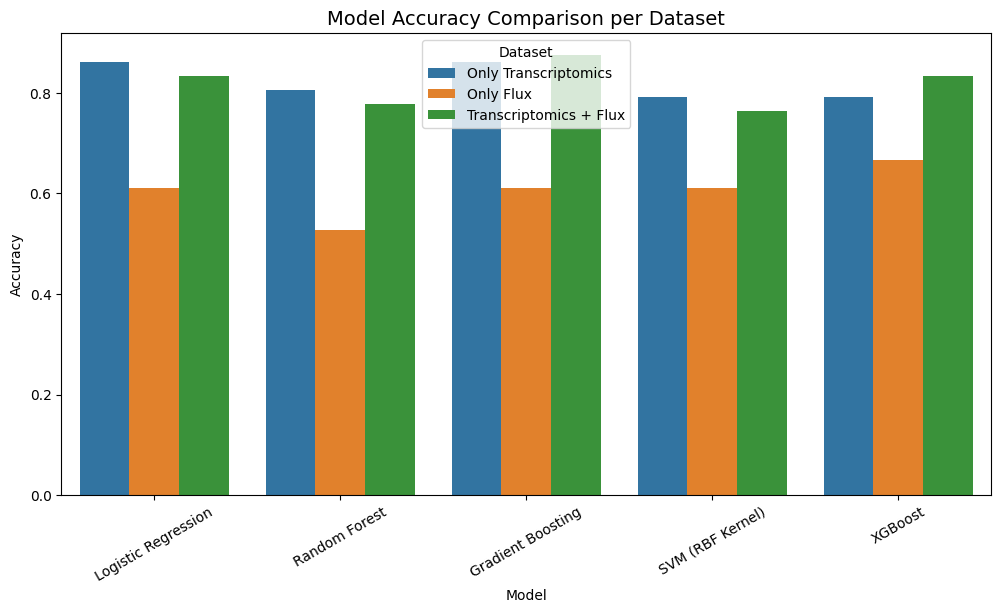

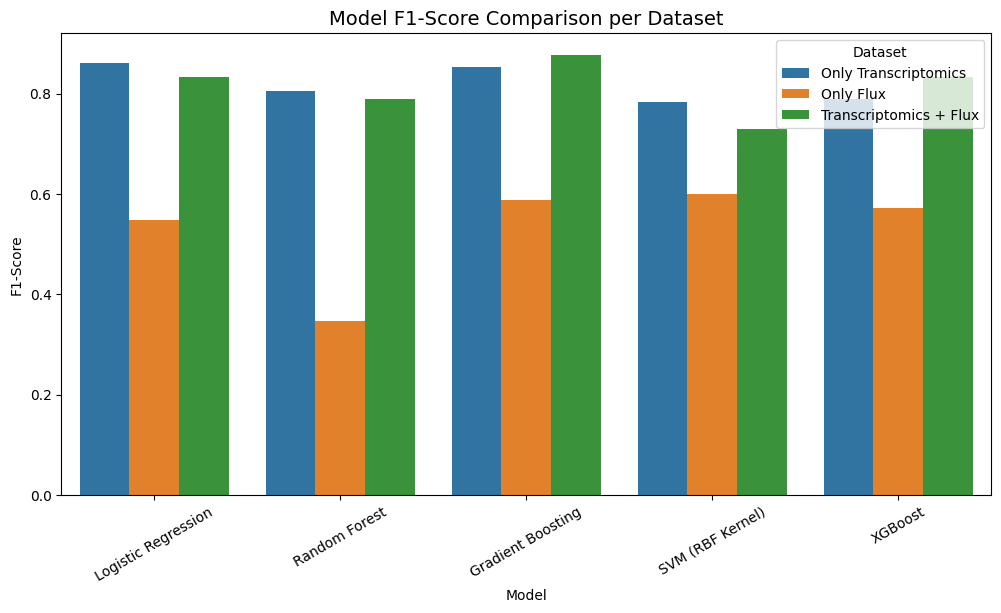

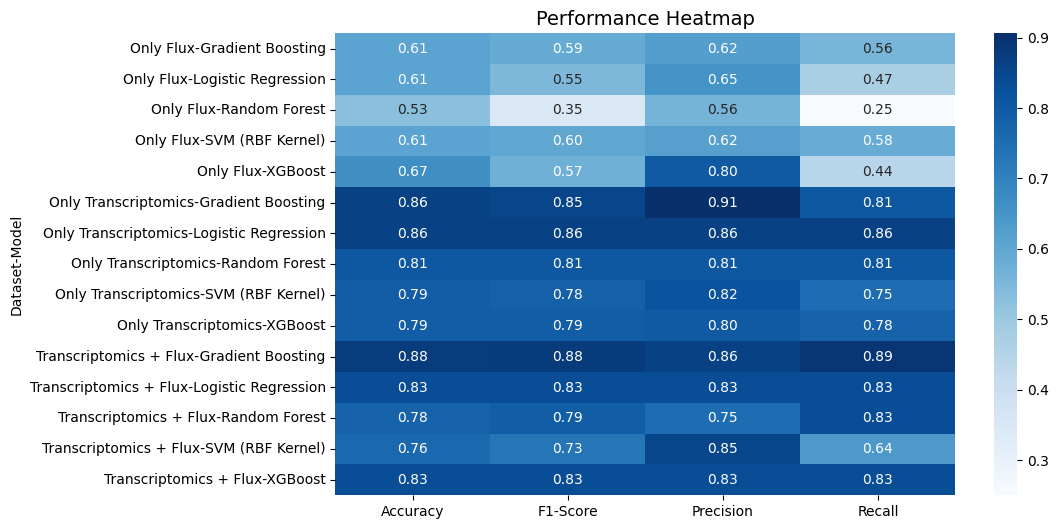

In [50]:
# -----------------------------
# Flatten performance_results
# -----------------------------
records = []
for dataset, models in performance_results.items():
    for model_name, metrics in models.items():
        records.append({
            "Dataset": dataset,
            "Model": model_name,
            "Accuracy": metrics["accuracy"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1-Score": metrics["f1_score"]
        })

perf_df = pd.DataFrame(records)
print(perf_df)

# -----------------------------
# Visualization
# -----------------------------
plt.figure(figsize=(12, 6))
sns.barplot(data=perf_df, x="Model", y="Accuracy", hue="Dataset")
plt.title("Model Accuracy Comparison per Dataset", fontsize=14)
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.legend(title="Dataset")
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=perf_df, x="Model", y="F1-Score", hue="Dataset")
plt.title("Model F1-Score Comparison per Dataset", fontsize=14)
plt.ylabel("F1-Score")
plt.xticks(rotation=30)
plt.legend(title="Dataset")
plt.show()

# Heatmap for detailed metrics
pivot = perf_df.pivot_table(index=["Dataset", "Model"], 
                            values=["Accuracy", "Precision", "Recall", "F1-Score"])
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Performance Heatmap", fontsize=14)
plt.show()


In [ ]:
# Make output folder
out_dir = "overall"
os.makedirs(out_dir, exist_ok=True)

# 1) Accuracy bar plot
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=perf_df, x="Model", y="Accuracy", hue="Dataset")
plt.title("Model Accuracy Comparison per Dataset", fontsize=14)
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.legend(title="Dataset")
plt.tight_layout()
acc_path = os.path.join(out_dir, "accuracy_by_model_dataset.pdf")
plt.savefig(acc_path, bbox_inches="tight")
plt.close()
print("✅ Saved:", acc_path)

# 2) F1-score bar plot
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=perf_df, x="Model", y="F1-Score", hue="Dataset")
plt.title("Model F1-Score Comparison per Dataset", fontsize=14)
plt.ylabel("F1-Score")
plt.xticks(rotation=30)
plt.legend(title="Dataset")
plt.tight_layout()
f1_path = os.path.join(out_dir, "f1_by_model_dataset.pdf")
plt.savefig(f1_path, bbox_inches="tight")
plt.close()
print("✅ Saved:", f1_path)

# 3) Performance heatmap
pivot = perf_df.pivot_table(index=["Dataset", "Model"],
                            values=["Accuracy", "Precision", "Recall", "F1-Score"])
plt.figure(figsize=(10, 6))
ax = sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Performance Heatmap", fontsize=14)
plt.tight_layout()
heatmap_path = os.path.join(out_dir, "performance_heatmap.pdf")
plt.savefig(heatmap_path, bbox_inches="tight")
plt.close()
print("✅ Saved:", heatmap_path)
